In [1]:
# Load Data (Again)

!pip install -q pyreadr
!git clone -q https://github.com/warint/tiger_woods.git

import random
import numpy as np
import pandas as pd
import pyreadr
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)   # should say "cuda" - if not, switch Colab to a GPU runtime

df = pyreadr.read_r("tiger_woods/data/old/tiger_woods_sentiment.RDS")[None]

Device: cuda


In [2]:
# Preprocessing (Again)

df = df.sort_values(["Tournament_Year", "Tournament_Order", "Round_Number"])
df["next_score"] = df.groupby(["Tournament_Year", "Permanent_Tournament_Number"])["Round_Score"].shift(-1)
df["Interview_Text"] = df["Interview_Text"].fillna("").str.strip()
df = df[df["Interview_Text"] != ""]
df = df.dropna(subset=["next_score"])
df["label"] = (df["next_score"] <= 69).astype(int)
print("Rows:", len(df))

Rows: 380


In [3]:
# Train / validation / test split (4b)

# Split by time. The TEST set (2014-2020) is exactly the same as in Part 3,
# so the deep learning model and the baselines are compared on the same data.
train = df[df["Tournament_Year"] <= 2011]
val = df[(df["Tournament_Year"] >= 2012) & (df["Tournament_Year"] <= 2013)]
test = df[df["Tournament_Year"] >= 2014]

for name, d in [("Train (1996-2011)", train), ("Validation (2012-2013)", val), ("Test (2014-2020)", test)]:
    print(f"{name}: {len(d)} rows, {d['label'].mean():.0%} label 1")

Train (1996-2011): 198 rows, 56% label 1
Validation (2012-2013): 89 rows, 43% label 1
Test (2014-2020): 93 rows, 42% label 1


In [4]:
# Architecture and tokenization (4a)

# Architecture: DistilBERT (a pre-trained Transformer) with a classification head.
#  - Transfer learning: it already understands English from pre-training, which we
#    need because we only have ~200 training interviews (too few to train an LSTM/CNN
#    from scratch).
#  - Self-attention reads every word in context, unlike TF-IDF in the baseline.
#  - 40% smaller and 60% faster than BERT, so it trains in minutes on a free Colab GPU.
MODEL_NAME = "distilbert-base-uncased"
MAX_LEN = 512          # DistilBERT's limit
HEAD, TAIL = 128, 382  # "head + tail" truncation (Sun et al., 2019): keep the start and end

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode(texts):
    """Tokenize; for long interviews keep the first 128 and last 382 tokens."""
    ids_list, mask_list = [], []
    for text in texts:
        ids = tokenizer(text, add_special_tokens=False)["input_ids"]
        if len(ids) > MAX_LEN - 2:
            ids = ids[:HEAD] + ids[-TAIL:]
        ids = [tokenizer.cls_token_id] + ids + [tokenizer.sep_token_id]
        mask = [1] * len(ids)
        pad = MAX_LEN - len(ids)
        ids_list.append(ids + [tokenizer.pad_token_id] * pad)
        mask_list.append(mask + [0] * pad)
    return torch.tensor(ids_list), torch.tensor(mask_list)

def make_dataset(d):
    ids, mask = encode(d["Interview_Text"].tolist())
    return TensorDataset(ids, mask, torch.tensor(d["label"].values))

train_ds, val_ds, test_ds = make_dataset(train), make_dataset(val), make_dataset(test)
print("Tokenized:", len(train_ds), len(val_ds), len(test_ds))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1365 > 512). Running this sequence through the model will result in indexing errors


Tokenized: 198 89 93


In [5]:
# Training functions (4c)

# Key choices:
#  - Loss: cross-entropy (standard for classification)
#  - Metrics: ROC-AUC (main, same as Part 3), accuracy, precision, recall, F1
#  - Optimizer: AdamW with a linear learning-rate schedule and 10% warm-up
#  - Batch size: 16 | Max epochs: 8
#  - Regularization: dropout 0.2 in the classifier, weight decay 0.01,
#    early stopping (stop if validation ROC-AUC doesn't improve for 2 epochs)
BATCH_SIZE = 16
MAX_EPOCHS = 8
PATIENCE = 2
WEIGHT_DECAY = 0.01
DROPOUT = 0.2

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def predict(model, ds):
    model.eval()
    probs = []
    with torch.no_grad():
        for ids, mask, _ in DataLoader(ds, batch_size=32):
            logits = model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
            probs.append(torch.softmax(logits, dim=1)[:, 1].cpu())
    return torch.cat(probs).numpy()

def metrics(y, prob, name):
    pred = (prob >= 0.5).astype(int)
    return {"Model": name, "Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0), "ROC-AUC": roc_auc_score(y, prob)}

def train_model(lr, seed=42, verbose=True):
    set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, seq_classif_dropout=DROPOUT).to(device)
    loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    steps = len(loader) * MAX_EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * steps), steps)
    loss_fn = torch.nn.CrossEntropyLoss()

    history, best_auc, best_state, bad_epochs = [], -1, None, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        total = 0
        for ids, mask, y in loader:
            optimizer.zero_grad()
            logits = model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
            loss = loss_fn(logits, y.to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step(); scheduler.step()
            total += loss.item() * len(y)
        train_loss = total / len(train_ds)
        val_auc = roc_auc_score(val["label"], predict(model, val_ds))
        history.append({"epoch": epoch, "train_loss": train_loss, "val_auc": val_auc})
        if verbose:
            print(f"  epoch {epoch}: train loss {train_loss:.3f} | val ROC-AUC {val_auc:.3f}")

        # Early stopping: keep the best epoch, stop after PATIENCE bad epochs
        if val_auc > best_auc:
            best_auc, bad_epochs = val_auc, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                if verbose: print("  early stopping")
                break
    model.load_state_dict(best_state)
    return model, best_auc, pd.DataFrame(history)

In [6]:
# Hyperparameter tuning - learning rate grid search (4c)

# Manual grid search over the learning rate (the most important setting for
# fine-tuning). Each option is judged on the VALIDATION set only.
tuning = []
for lr in [1e-5, 2e-5, 3e-5, 5e-5]:
    print(f"Learning rate {lr}")
    _, val_auc, hist = train_model(lr)
    tuning.append({"learning_rate": lr, "best_val_auc": val_auc, "epochs_run": len(hist)})
tuning = pd.DataFrame(tuning)
best_lr = tuning.loc[tuning["best_val_auc"].idxmax(), "learning_rate"]
print(tuning.to_string(index=False, formatters={"learning_rate": "{:.0e}".format,
                                                "best_val_auc": "{:.3f}".format}))
print("Best learning rate:", best_lr)

Learning rate 1e-05


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1: train loss 0.695 | val ROC-AUC 0.406
  epoch 2: train loss 0.683 | val ROC-AUC 0.455
  epoch 3: train loss 0.683 | val ROC-AUC 0.483
  epoch 4: train loss 0.675 | val ROC-AUC 0.483
  epoch 5: train loss 0.673 | val ROC-AUC 0.485
  epoch 6: train loss 0.655 | val ROC-AUC 0.485
  epoch 7: train loss 0.648 | val ROC-AUC 0.467
  epoch 8: train loss 0.647 | val ROC-AUC 0.466
  early stopping
Learning rate 2e-05


... (5 outputs left out)

  epoch 1: train loss 0.697 | val ROC-AUC 0.492
  epoch 2: train loss 0.682 | val ROC-AUC 0.489
  epoch 3: train loss 0.671 | val ROC-AUC 0.506
  epoch 4: train loss 0.629 | val ROC-AUC 0.476
  epoch 5: train loss 0.516 | val ROC-AUC 0.471
  early stopping
Learning rate 5e-05


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1: train loss 0.699 | val ROC-AUC 0.521
  epoch 2: train loss 0.683 | val ROC-AUC 0.462
  epoch 3: train loss 0.656 | val ROC-AUC 0.460
  early stopping
learning_rate best_val_auc  epochs_run
        1e-05        0.485           8
        2e-05        0.518           4
        3e-05        0.506           5
        5e-05        0.521           3
Best learning rate: 5e-05


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1: train loss 0.699 | val ROC-AUC 0.521
  epoch 2: train loss 0.683 | val ROC-AUC 0.462
  epoch 3: train loss 0.656 | val ROC-AUC 0.460
  early stopping


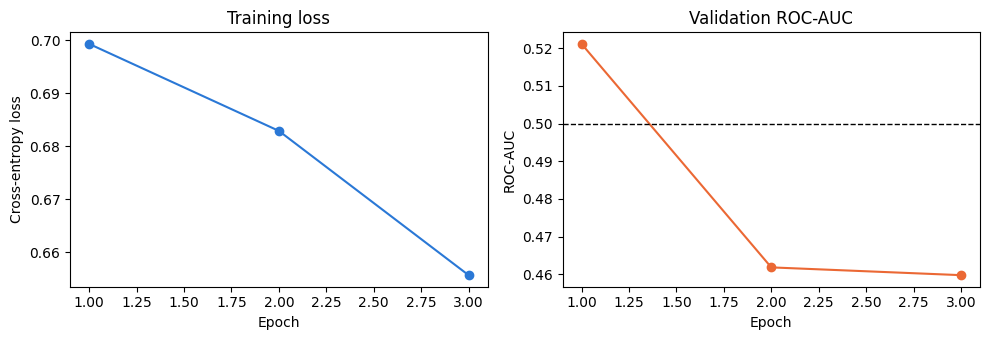

In [7]:
# Train the final model and plot learning curves
model, best_val_auc, history = train_model(best_lr)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history["epoch"], history["train_loss"], marker="o", color="#2a78d6")
ax[0].set(title="Training loss", xlabel="Epoch", ylabel="Cross-entropy loss")
ax[1].plot(history["epoch"], history["val_auc"], marker="o", color="#eb6834")
ax[1].axhline(0.5, color="black", linestyle="--", linewidth=1)
ax[1].set(title="Validation ROC-AUC", xlabel="Epoch", ylabel="ROC-AUC")
plt.tight_layout()
plt.show()

Model        DistilBERT (fine-tuned)
Accuracy                    0.419355
Precision                   0.419355
Recall                           1.0
F1                          0.590909
ROC-AUC                      0.54416
dtype: object


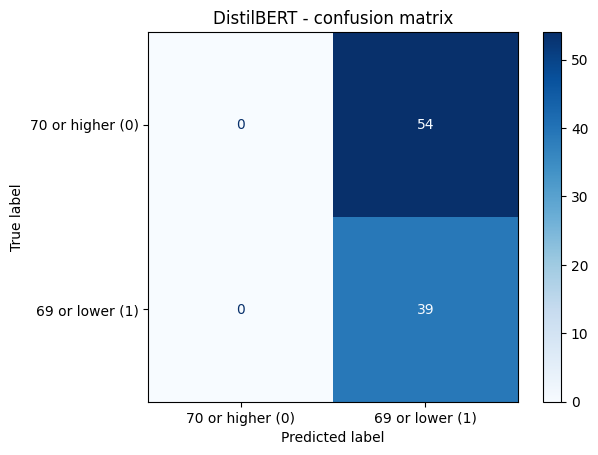

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Test ROC-AUC over 3 seeds: mean 0.579, std 0.018


In [8]:
# Evaluate on the test set

test_prob = predict(model, test_ds)
dl_result = metrics(test["label"].values, test_prob, "DistilBERT (fine-tuned)")
print(pd.Series(dl_result))

ConfusionMatrixDisplay.from_predictions(
    test["label"], (test_prob >= 0.5).astype(int),
    display_labels=["70 or higher (0)", "69 or lower (1)"], cmap="Blues")
plt.title("DistilBERT - confusion matrix")
plt.show()

# Small datasets make results depend on the random seed, so we also
# re-train with 3 seeds and report the average test ROC-AUC.
seed_aucs = []
for seed in [1, 2, 3]:
    m, _, _ = train_model(best_lr, seed=seed, verbose=False)
    seed_aucs.append(roc_auc_score(test["label"], predict(m, test_ds)))
    del m; torch.cuda.empty_cache()
print(f"Test ROC-AUC over 3 seeds: mean {np.mean(seed_aucs):.3f}, std {np.std(seed_aucs):.3f}")

                                 Model  Accuracy  Precision  Recall    F1  ROC-AUC
                        Majority class     0.419      0.419   1.000 0.591    0.500
                    Naive Bayes (text)     0.419      0.414   0.923 0.571    0.516
            Logistic Regression (text)     0.527      0.447   0.538 0.488    0.547
Logistic Regression (round score only)     0.559      0.472   0.436 0.453    0.617
               DistilBERT (fine-tuned)     0.419      0.419   1.000 0.591    0.544


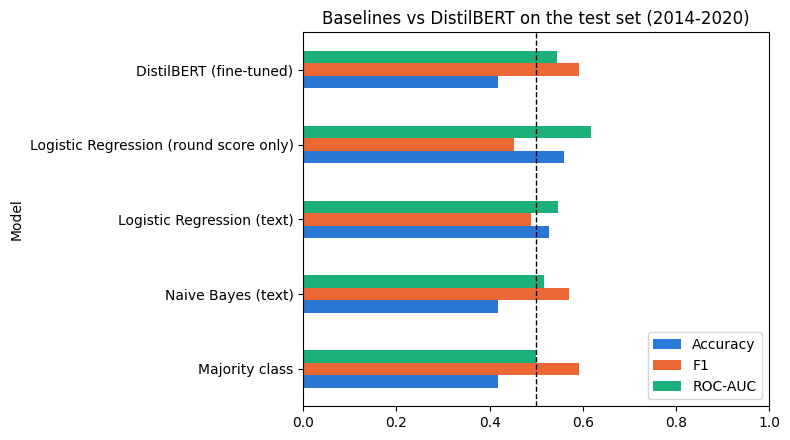

Saved final_comparison.csv


In [9]:
# Compare with the baselines (4d)

# Baseline numbers from Part 3 (same 2014-2020 test set).
baselines = pd.DataFrame([
    {"Model": "Majority class", "Accuracy": 0.419, "Precision": 0.419, "Recall": 1.000, "F1": 0.591, "ROC-AUC": 0.500},
    {"Model": "Naive Bayes (text)", "Accuracy": 0.419, "Precision": 0.414, "Recall": 0.923, "F1": 0.571, "ROC-AUC": 0.516},
    {"Model": "Logistic Regression (text)", "Accuracy": 0.527, "Precision": 0.447, "Recall": 0.538, "F1": 0.488, "ROC-AUC": 0.547},
    {"Model": "Logistic Regression (round score only)", "Accuracy": 0.559, "Precision": 0.472, "Recall": 0.436, "F1": 0.453, "ROC-AUC": 0.617},
])
comparison = pd.concat([baselines, pd.DataFrame([dl_result])], ignore_index=True).round(3)
print(comparison.to_string(index=False))

comparison.set_index("Model")[["Accuracy", "F1", "ROC-AUC"]].plot(
    kind="barh", figsize=(8, 4.5), color=["#2a78d6", "#eb6834", "#1baf7a"])
plt.axvline(0.5, color="black", linestyle="--", linewidth=1)
plt.title("Baselines vs DistilBERT on the test set (2014-2020)")
plt.xlim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

comparison.to_csv("final_comparison.csv", index=False)
print("Saved final_comparison.csv")